In [1]:
from simulation import NanobotSimulator 
from diseases import DiseaseSimulator
from plots import AnomalyVisualizer
from drift_detection import AnomalyDetector

In [2]:
# sim = NanobotSimulator(alpha=0.3, beta=0.1)

# final_report_ph = sim.run_energy_simulation(
#     param="ph", 
#     mode="zone", 
#     is_timeseries=True
# )

# if final_report_ph is not None and not final_report_ph.empty:
#     print(final_report_ph.to_string(index=False))
# else:
#     print("Simulation completed: No samples met the target confidence threshold.")

In [3]:
# sim = NanobotSimulator(alpha=0.3, beta=0.01)

# final_report_temp = sim.run_energy_simulation(
#     param="temp", 
#     mode="zone", 
#     is_timeseries=True
# )

# if final_report_temp is not None and not final_report_temp.empty:
#     print(final_report_temp.to_string(index=False))
# else:
#     print("Simulation completed: No samples met the target confidence threshold.")

In [4]:
# sim = NanobotSimulator(alpha=0.3, beta=0.1)

# final_report_combined = sim.run_combined_energy_ts(mode='zone')

# if final_report_combined is not None and not final_report_combined.empty:
#     print(final_report_combined.to_string(index=False))
# else:
#     print("Simulation completed: No samples met the target confidence threshold.")

--- 1. Running Disease Simulation (Stroke in Zone 7) ---
[STROKE_PH] Velocity: 1.0h | Random Onset: Hour 14.6 | Peak: Hour 15.6

--- 2. Running Whole-Body Anomaly Detection ---

--- Detection Results ---
Disease actually started at: Hour 14.58

[RAW STREAM ALERTS]
  --> ZONE 7 ALERT:
      - Flagged at Hour 15.07 | Delay: 29.5 min

[AGGREGATED STREAM ALERTS]
  --> ZONE 7 ALERT:
      - Flagged at Hour 16.82 | Delay: 134.4 min

--- 3. Generating Visualization ---


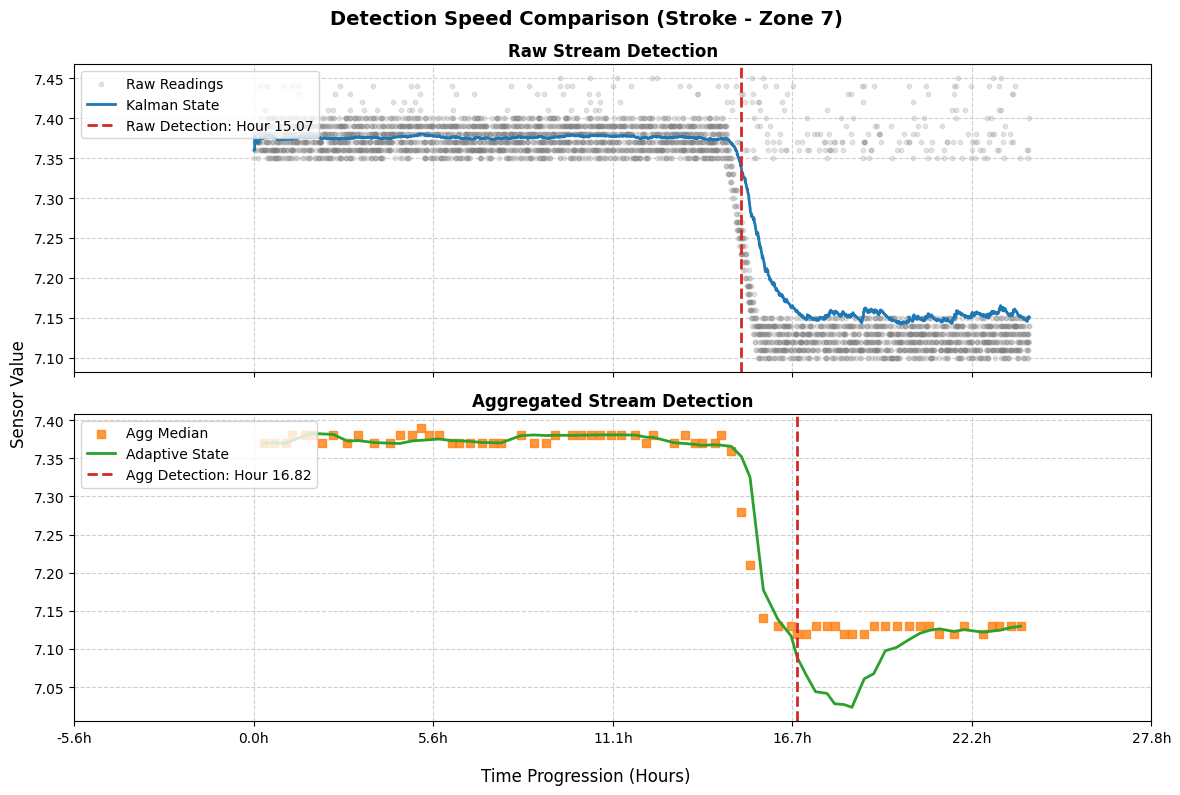

In [5]:
# --- 1. ACTIVE DISEASE: STROKE (pH) ---
TARGET_ZONE = 7          
ALPHA_NOISE = 0.3
BETA_ERROR = 0.10
TARGET_CONF = 70.0       
SAFE_START = 1800

print(f"--- 1. Running Disease Simulation (Stroke in Zone {TARGET_ZONE}) ---")
simulator = DiseaseSimulator()

raw_df, agg_df, t_start = simulator.run_single_disease(
    alpha=ALPHA_NOISE, 
    beta=BETA_ERROR, 
    disease_key='stroke_ph',
    target_confidence=TARGET_CONF,
    safe_start_time=SAFE_START
)

if agg_df is not None and not agg_df.empty:
    print(f"\n--- 2. Running Whole-Body Anomaly Detection ---")
    
    detector = AnomalyDetector(
        alpha=ALPHA_NOISE, 
        beta=BETA_ERROR,
        target_confidence=TARGET_CONF,
        raw_drift_threshold=3.5,
        agg_persistence=4,
        agg_abs_drift=0.10
    )

    processed_raw_df, all_raw_alerts = detector.detect_raw_stream(raw_df)
    processed_agg_df, all_agg_alerts = detector.detect_aggregated_stream(agg_df)

    print("\n--- Detection Results ---")
    print(f"Disease actually started at: Hour {t_start/3600:.2f}")
    
    def print_zone_alerts(alert_dict, stream_name):
        print(f"\n[{stream_name} ALERTS]")
        if not alert_dict:
            print("  No anomalies detected in any zone.")
            return
            
        for zone_id, t_det in alert_dict.items():
            print(f"  --> ZONE {zone_id} ALERT:")
            if t_det is not None:
                delay = t_det - t_start
                status = f"False Positive ({-delay/60:.1f} min early)" if delay < 0 else f"Delay: {delay/60:.1f} min"
                print(f"      - Flagged at Hour {t_det/3600:.2f} | {status}")

    print_zone_alerts(all_raw_alerts, "RAW STREAM")
    print_zone_alerts(all_agg_alerts, "AGGREGATED STREAM")

    print(f"\n--- 3. Generating Visualization ---")
    visualizer = AnomalyVisualizer()
    
    plot_det_raw = all_raw_alerts.get(TARGET_ZONE, None)
    plot_det_agg = all_agg_alerts.get(TARGET_ZONE, None)
    
    plot_raw_df = processed_raw_df[processed_raw_df['Zone'] == TARGET_ZONE]
    plot_agg_df = processed_agg_df[processed_agg_df['Zone'] == TARGET_ZONE]

    visualizer.plot_comparison(
        raw_df=plot_raw_df, 
        agg_df=plot_agg_df, 
        det_raw=plot_det_raw, 
        det_agg=plot_det_agg, 
        title=f"Detection Speed Comparison (Stroke - Zone {TARGET_ZONE})"
    )
else:
    print("Simulation failed or returned empty data.")

--- 1. Running Healthy Baseline (Monitoring Zone 7) ---
[STROKE_PH] Velocity: 1.0h | Random Onset: Hour 24.0 | Peak: Hour 25.0

--- 2. Running Whole-Body Anomaly Detection ---

--- Detection Results ---

[RAW STREAM ALERTS]
  No anomalies detected in any zone. (Expected Healthy Behavior)

[AGGREGATED STREAM ALERTS]
  No anomalies detected in any zone. (Expected Healthy Behavior)

--- 3. Generating Visualization ---


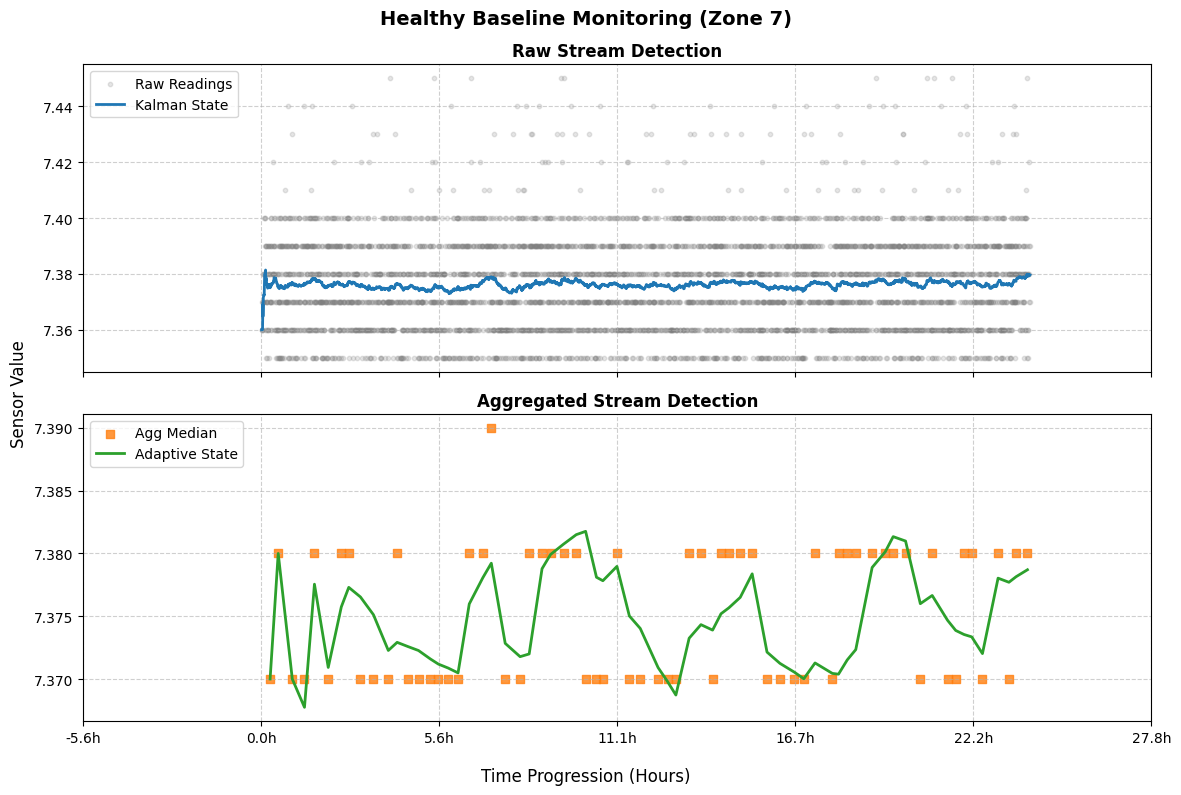

In [6]:
# --- 2. HEALTHY PATIENT (pH Monitoring) ---
TARGET_ZONE = 7          
ALPHA_NOISE = 0.3
BETA_ERROR = 0.10
TARGET_CONF = 70.0       
SAFE_START = 86400       # Pushed beyond 24h to simulate healthy patient

print(f"--- 1. Running Healthy Baseline (Monitoring Zone {TARGET_ZONE}) ---")
simulator = DiseaseSimulator()

raw_df, agg_df, t_start = simulator.run_single_disease(
    alpha=ALPHA_NOISE, 
    beta=BETA_ERROR, 
    disease_key='stroke_ph',
    target_confidence=TARGET_CONF,
    safe_start_time=SAFE_START
)

if agg_df is not None and not agg_df.empty:
    print(f"\n--- 2. Running Whole-Body Anomaly Detection ---")
    
    detector = AnomalyDetector(
        alpha=ALPHA_NOISE, 
        beta=BETA_ERROR,
        target_confidence=TARGET_CONF,
        raw_drift_threshold=3.5,
        agg_persistence=4,
        agg_abs_drift=0.10
    )

    processed_raw_df, all_raw_alerts = detector.detect_raw_stream(raw_df)
    processed_agg_df, all_agg_alerts = detector.detect_aggregated_stream(agg_df)

    print("\n--- Detection Results ---")
    
    def print_zone_alerts(alert_dict, stream_name):
        print(f"\n[{stream_name} ALERTS]")
        if not alert_dict:
            print("  No anomalies detected in any zone. (Expected Healthy Behavior)")
            return
            
        for zone_id, t_det in alert_dict.items():
            print(f"  --> ZONE {zone_id} ALERT:")
            if t_det is not None:
                print(f"      - FALSE POSITIVE: Flagged at Hour {t_det/3600:.2f}")

    print_zone_alerts(all_raw_alerts, "RAW STREAM")
    print_zone_alerts(all_agg_alerts, "AGGREGATED STREAM")

    print(f"\n--- 3. Generating Visualization ---")
    visualizer = AnomalyVisualizer()
    
    plot_det_raw = all_raw_alerts.get(TARGET_ZONE, None)
    plot_det_agg = all_agg_alerts.get(TARGET_ZONE, None)
    
    plot_raw_df = processed_raw_df[processed_raw_df['Zone'] == TARGET_ZONE]
    plot_agg_df = processed_agg_df[processed_agg_df['Zone'] == TARGET_ZONE]

    visualizer.plot_comparison(
        raw_df=plot_raw_df, 
        agg_df=plot_agg_df, 
        det_raw=plot_det_raw, 
        det_agg=plot_det_agg, 
        title=f"Healthy Baseline Monitoring (Zone {TARGET_ZONE})"
    )

--- 1. Running Disease Simulation (DVT in Zone 19) ---
[DVT_TEMP] Velocity: 8.0h | Random Onset: Hour 8.1 | Peak: Hour 16.1

--- 2. Running Whole-Body Anomaly Detection ---

--- Detection Results ---
Disease actually started at: Hour 8.08

[RAW STREAM ALERTS]
  --> ZONE 1 ALERT:
      - Flagged at Hour 0.54 | False Positive (452.5 min early)
  --> ZONE 2 ALERT:
      - Flagged at Hour 3.82 | False Positive (255.7 min early)
  --> ZONE 4 ALERT:
      - Flagged at Hour 4.34 | False Positive (224.4 min early)
  --> ZONE 8 ALERT:
      - Flagged at Hour 19.91 | Delay: 709.6 min
  --> ZONE 9 ALERT:
      - Flagged at Hour 11.20 | Delay: 186.7 min
  --> ZONE 11 ALERT:
      - Flagged at Hour 16.67 | Delay: 515.2 min
  --> ZONE 12 ALERT:
      - Flagged at Hour 7.69 | False Positive (23.5 min early)
  --> ZONE 13 ALERT:
      - Flagged at Hour 5.27 | False Positive (169.1 min early)
  --> ZONE 15 ALERT:
      - Flagged at Hour 3.64 | False Positive (266.5 min early)
  --> ZONE 19 ALERT:
     

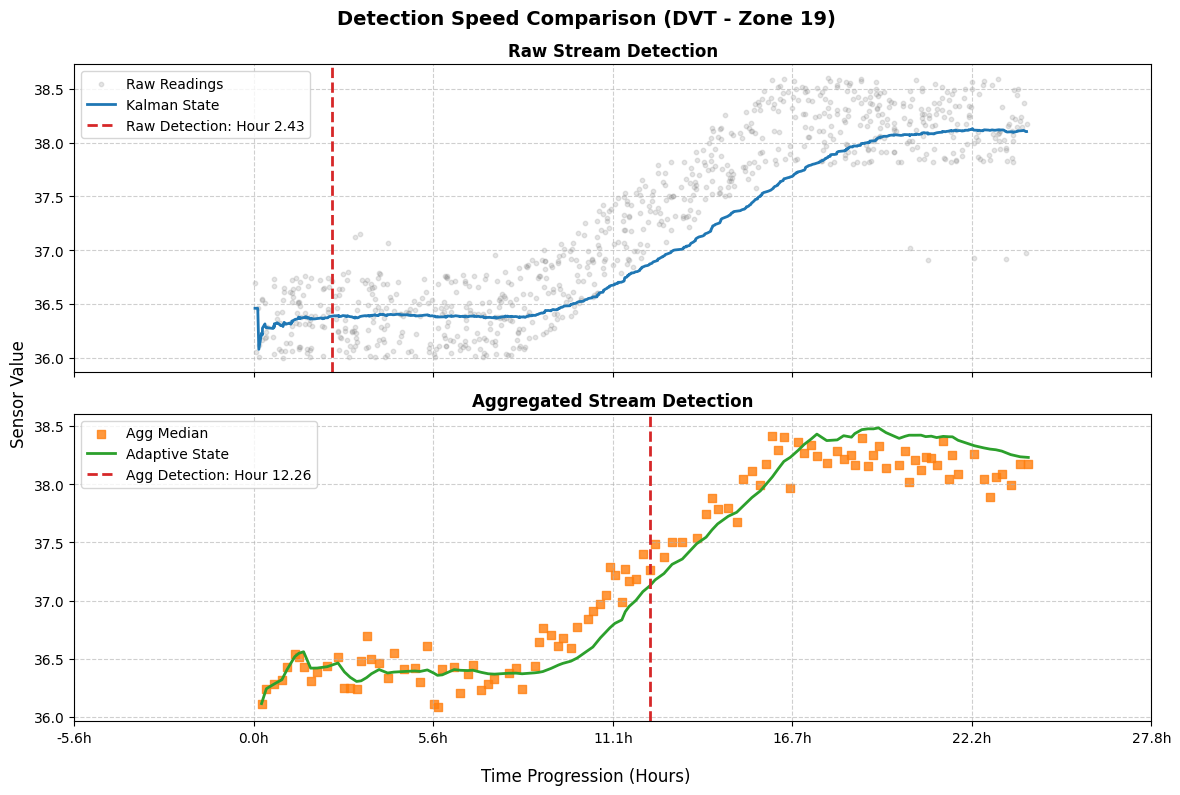

In [7]:
# --- 3. ACTIVE DISEASE: DVT (Temp) ---
TARGET_ZONE = 19          
ALPHA_NOISE = 0.3
BETA_ERROR = 0.01
TARGET_CONF = 70.0       
SAFE_START = 1800        

print(f"--- 1. Running Disease Simulation (DVT in Zone {TARGET_ZONE}) ---")
simulator = DiseaseSimulator()

raw_df, agg_df, t_start = simulator.run_single_disease(
    alpha=ALPHA_NOISE, 
    beta=BETA_ERROR, 
    disease_key='dvt_temp',
    target_confidence=TARGET_CONF,
    safe_start_time=SAFE_START
)

if agg_df is not None and not agg_df.empty:
    print(f"\n--- 2. Running Whole-Body Anomaly Detection ---")
    
    detector = AnomalyDetector(
        alpha=ALPHA_NOISE, 
        beta=BETA_ERROR,
        target_confidence=TARGET_CONF,
        raw_drift_threshold=3.5,
        agg_persistence=4,
        agg_abs_drift=0.80
    )

    processed_raw_df, all_raw_alerts = detector.detect_raw_stream(raw_df)
    processed_agg_df, all_agg_alerts = detector.detect_aggregated_stream(agg_df)

    print("\n--- Detection Results ---")
    print(f"Disease actually started at: Hour {t_start/3600:.2f}")
    
    def print_zone_alerts(alert_dict, stream_name):
        print(f"\n[{stream_name} ALERTS]")
        if not alert_dict:
            print("  No anomalies detected in any zone.")
            return
            
        for zone_id, t_det in alert_dict.items():
            print(f"  --> ZONE {zone_id} ALERT:")
            if t_det is not None:
                delay = t_det - t_start
                status = f"False Positive ({-delay/60:.1f} min early)" if delay < 0 else f"Delay: {delay/60:.1f} min"
                print(f"      - Flagged at Hour {t_det/3600:.2f} | {status}")

    print_zone_alerts(all_raw_alerts, "RAW STREAM")
    print_zone_alerts(all_agg_alerts, "AGGREGATED STREAM")

    print(f"\n--- 3. Generating Visualization ---")
    visualizer = AnomalyVisualizer()
    
    plot_det_raw = all_raw_alerts.get(TARGET_ZONE, None)
    plot_det_agg = all_agg_alerts.get(TARGET_ZONE, None)
    
    plot_raw_df = processed_raw_df[processed_raw_df['Zone'] == TARGET_ZONE]
    plot_agg_df = processed_agg_df[processed_agg_df['Zone'] == TARGET_ZONE]

    visualizer.plot_comparison(
        raw_df=plot_raw_df, 
        agg_df=plot_agg_df, 
        det_raw=plot_det_raw, 
        det_agg=plot_det_agg, 
        title=f"Detection Speed Comparison (DVT - Zone {TARGET_ZONE})"
    )

--- 1. Running Healthy Baseline (Monitoring Zone 19) ---
[DVT_TEMP] Velocity: 8.0h | Random Onset: Hour 24.0 | Peak: Hour 32.0

--- 2. Running Whole-Body Anomaly Detection ---

--- Detection Results ---

[RAW STREAM ALERTS]
  --> ZONE 1 ALERT:
      - FALSE POSITIVE: Flagged at Hour 2.91
  --> ZONE 2 ALERT:
      - FALSE POSITIVE: Flagged at Hour 2.45
  --> ZONE 4 ALERT:
      - FALSE POSITIVE: Flagged at Hour 19.73
  --> ZONE 7 ALERT:
      - FALSE POSITIVE: Flagged at Hour 13.50
  --> ZONE 8 ALERT:
      - FALSE POSITIVE: Flagged at Hour 17.90
  --> ZONE 13 ALERT:
      - FALSE POSITIVE: Flagged at Hour 4.42
  --> ZONE 14 ALERT:
      - FALSE POSITIVE: Flagged at Hour 5.41
  --> ZONE 18 ALERT:
      - FALSE POSITIVE: Flagged at Hour 2.87
  --> ZONE 19 ALERT:
      - FALSE POSITIVE: Flagged at Hour 6.01
  --> ZONE 20 ALERT:
      - FALSE POSITIVE: Flagged at Hour 0.22

[AGGREGATED STREAM ALERTS]
  No anomalies detected in any zone. (Expected Healthy Behavior)

--- 3. Generating Visual

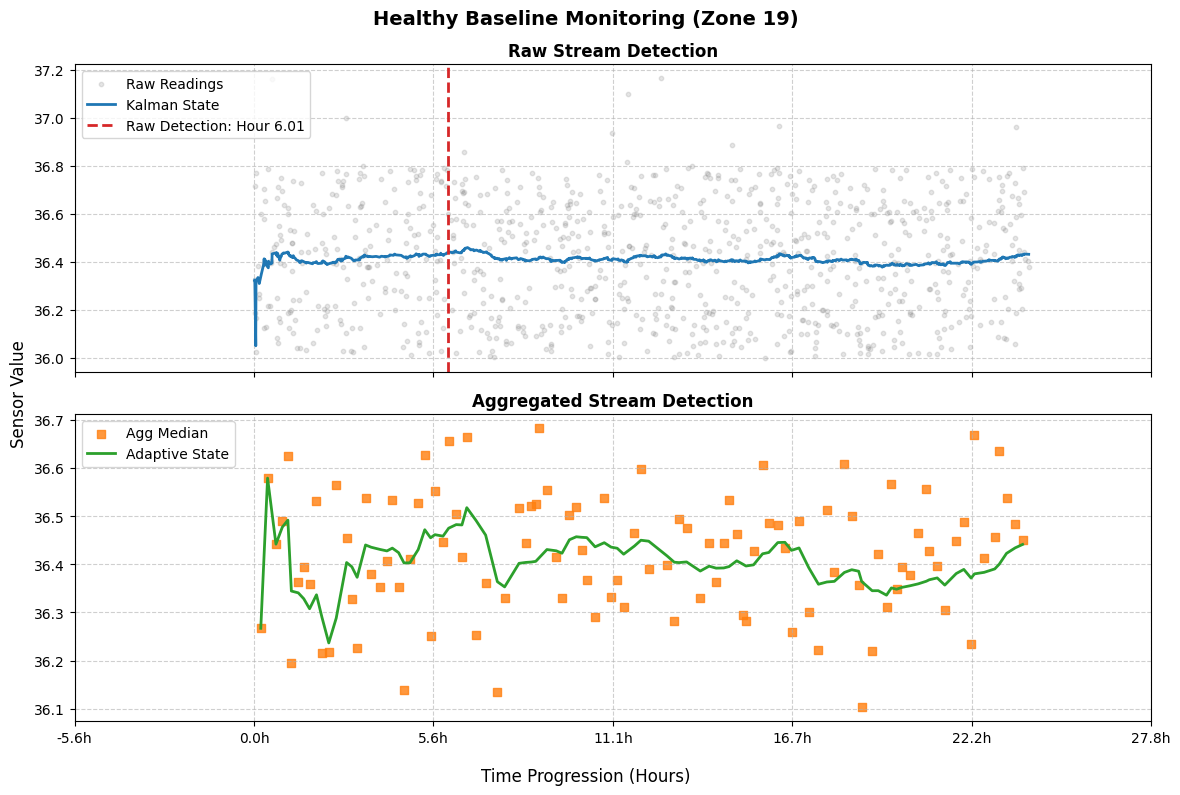

In [8]:
# --- 4. HEALTHY PATIENT (Temp Monitoring) ---
TARGET_ZONE = 19          
ALPHA_NOISE = 0.3
BETA_ERROR = 0.01
TARGET_CONF = 70.0       
SAFE_START = 86400       # Pushed beyond 24h

print(f"--- 1. Running Healthy Baseline (Monitoring Zone {TARGET_ZONE}) ---")
simulator = DiseaseSimulator()

raw_df, agg_df, t_start = simulator.run_single_disease(
    alpha=ALPHA_NOISE, 
    beta=BETA_ERROR, 
    disease_key='dvt_temp',
    target_confidence=TARGET_CONF,
    safe_start_time=SAFE_START
)

if agg_df is not None and not agg_df.empty:
    print(f"\n--- 2. Running Whole-Body Anomaly Detection ---")
    
    detector = AnomalyDetector(
        alpha=ALPHA_NOISE, 
        beta=BETA_ERROR,
        target_confidence=TARGET_CONF,
        raw_drift_threshold=3.5,
        agg_persistence=4,
        agg_abs_drift=0.80
    )

    processed_raw_df, all_raw_alerts = detector.detect_raw_stream(raw_df)
    processed_agg_df, all_agg_alerts = detector.detect_aggregated_stream(agg_df)

    print("\n--- Detection Results ---")
    
    def print_zone_alerts(alert_dict, stream_name):
        print(f"\n[{stream_name} ALERTS]")
        if not alert_dict:
            print("  No anomalies detected in any zone. (Expected Healthy Behavior)")
            return
            
        for zone_id, t_det in alert_dict.items():
            print(f"  --> ZONE {zone_id} ALERT:")
            if t_det is not None:
                print(f"      - FALSE POSITIVE: Flagged at Hour {t_det/3600:.2f}")

    print_zone_alerts(all_raw_alerts, "RAW STREAM")
    print_zone_alerts(all_agg_alerts, "AGGREGATED STREAM")

    print(f"\n--- 3. Generating Visualization ---")
    visualizer = AnomalyVisualizer()
    
    plot_det_raw = all_raw_alerts.get(TARGET_ZONE, None)
    plot_det_agg = all_agg_alerts.get(TARGET_ZONE, None)
    
    plot_raw_df = processed_raw_df[processed_raw_df['Zone'] == TARGET_ZONE]
    plot_agg_df = processed_agg_df[processed_agg_df['Zone'] == TARGET_ZONE]

    visualizer.plot_comparison(
        raw_df=plot_raw_df, 
        agg_df=plot_agg_df, 
        det_raw=plot_det_raw, 
        det_agg=plot_det_agg, 
        title=f"Healthy Baseline Monitoring (Zone {TARGET_ZONE})"
    )

--- 1. Running Disease Simulation (Pyelonephritis in Zone 16) ---
[PYELO_COMBINED] Velocity: 6.0h | Random Onset: Hour 9.4 | Peak: Hour 15.4

--- 2. Running Whole-Body Anomaly Detection ---

--- Detection Results ---
Disease actually started at: Hour 9.38

[RAW STREAM ALERTS]
  --> ZONE 1 ALERT:
      - PH Normal.
      - TEMP Flagged at Hour 0.28 | False Positive (545.9 min early)
  --> ZONE 2 ALERT:
      - PH Normal.
      - TEMP Flagged at Hour 1.99 | False Positive (443.5 min early)
  --> ZONE 3 ALERT:
      - PH Normal.
      - TEMP Flagged at Hour 0.76 | False Positive (517.3 min early)
  --> ZONE 4 ALERT:
      - PH Normal.
      - TEMP Flagged at Hour 5.59 | False Positive (227.5 min early)
  --> ZONE 6 ALERT:
      - PH Normal.
      - TEMP Flagged at Hour 16.42 | Delay: 422.2 min
  --> ZONE 7 ALERT:
      - PH Normal.
      - TEMP Flagged at Hour 2.36 | False Positive (421.0 min early)
  --> ZONE 8 ALERT:
      - PH Normal.
      - TEMP Flagged at Hour 0.43 | False Positive 

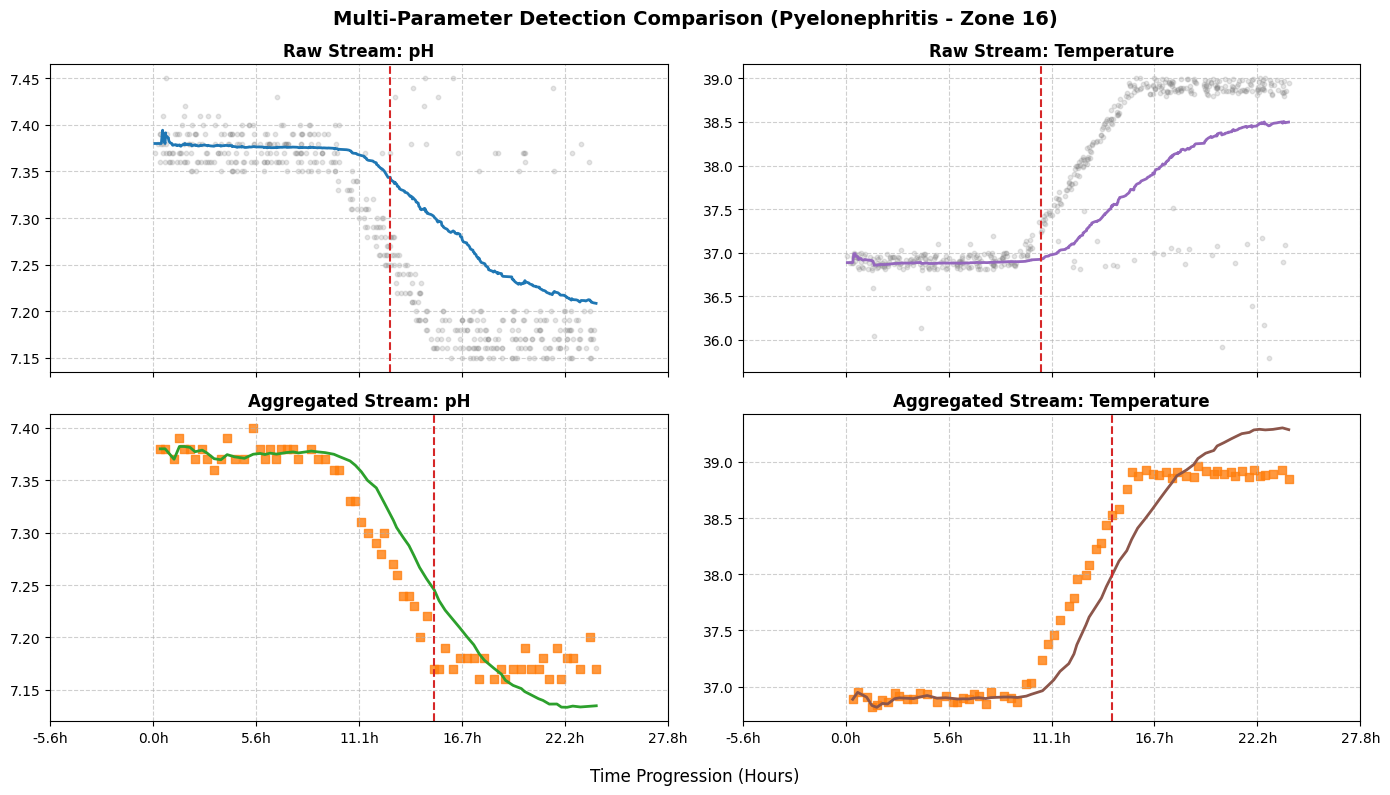

In [9]:
# --- 5. ACTIVE DISEASE: PYELONEPHRITIS (Combined) ---
TARGET_ZONE = 16          
ALPHA_NOISE = 0.3
BETA_ERROR = 0.10
TARGET_CONF = 70.0       
SAFE_START = 1800        

print(f"--- 1. Running Disease Simulation (Pyelonephritis in Zone {TARGET_ZONE}) ---")
simulator = DiseaseSimulator()

raw_df, agg_df, t_start = simulator.run_combined_disease(
    alpha=ALPHA_NOISE, 
    beta=BETA_ERROR, 
    disease_key='pyelo_combined',
    target_confidence=TARGET_CONF,
    safe_start_time=SAFE_START
)

if agg_df is not None and not agg_df.empty:
    print(f"\n--- 2. Running Whole-Body Anomaly Detection ---")
    
    detector = AnomalyDetector(
        alpha=ALPHA_NOISE, 
        beta=BETA_ERROR,
        target_confidence=TARGET_CONF,
        raw_drift_threshold=3.5,
        agg_persistence=4,
        agg_abs_drift_ph=0.10,
        agg_abs_drift_temp=0.80
    )

    # Note: Uses detect_combined... methods
    processed_raw_df, all_raw_alerts = detector.detect_combined_raw_stream(raw_df)
    processed_agg_df, all_agg_alerts = detector.detect_combined_aggregated_stream(agg_df)

    print("\n--- Detection Results ---")
    print(f"Disease actually started at: Hour {t_start/3600:.2f}")
    
    def print_combined_alerts(alert_dict, stream_name):
        print(f"\n[{stream_name} ALERTS]")
        if not alert_dict:
            print("  No anomalies detected in any zone.")
            return
            
        for zone_id, times in alert_dict.items():
            print(f"  --> ZONE {zone_id} ALERT:")
            for param, t_det in times.items():
                if t_det is not None:
                    delay = t_det - t_start
                    status = f"False Positive ({-delay/60:.1f} min early)" if delay < 0 else f"Delay: {delay/60:.1f} min"
                    print(f"      - {param.upper()} Flagged at Hour {t_det/3600:.2f} | {status}")
                else:
                    print(f"      - {param.upper()} Normal.")

    print_combined_alerts(all_raw_alerts, "RAW STREAM")
    print_combined_alerts(all_agg_alerts, "AGGREGATED STREAM")

    print(f"\n--- 3. Generating Visualization ---")
    visualizer = AnomalyVisualizer()
    
    # Must pass dictionaries for combined visualization
    plot_det_raw = all_raw_alerts.get(TARGET_ZONE, {'ph': None, 'temp': None})
    plot_det_agg = all_agg_alerts.get(TARGET_ZONE, {'ph': None, 'temp': None})
    
    plot_raw_df = processed_raw_df[processed_raw_df['Zone'] == TARGET_ZONE]
    plot_agg_df = processed_agg_df[processed_agg_df['Zone'] == TARGET_ZONE]

    visualizer.plot_combined_comparison(
        raw_df=plot_raw_df, 
        agg_df=plot_agg_df, 
        det_raw=plot_det_raw, 
        det_agg=plot_det_agg, 
        title=f"Multi-Parameter Detection Comparison (Pyelonephritis - Zone {TARGET_ZONE})"
    )

--- 1. Running Healthy Baseline (Monitoring Zone 16) ---
[PYELO_COMBINED] Velocity: 6.0h | Random Onset: Hour 24.0 | Peak: Hour 30.0

--- 2. Running Whole-Body Anomaly Detection ---

--- Detection Results ---

[RAW STREAM ALERTS]
  --> ZONE 1 ALERT:
      - TEMP FALSE POSITIVE: Flagged at Hour 0.50
  --> ZONE 2 ALERT:
      - TEMP FALSE POSITIVE: Flagged at Hour 0.12
  --> ZONE 3 ALERT:
      - TEMP FALSE POSITIVE: Flagged at Hour 9.43
  --> ZONE 4 ALERT:
      - TEMP FALSE POSITIVE: Flagged at Hour 1.62
  --> ZONE 6 ALERT:
      - TEMP FALSE POSITIVE: Flagged at Hour 10.23
  --> ZONE 7 ALERT:
      - TEMP FALSE POSITIVE: Flagged at Hour 1.57
  --> ZONE 9 ALERT:
      - TEMP FALSE POSITIVE: Flagged at Hour 3.54
  --> ZONE 10 ALERT:
      - TEMP FALSE POSITIVE: Flagged at Hour 9.60
  --> ZONE 13 ALERT:
      - TEMP FALSE POSITIVE: Flagged at Hour 14.71
  --> ZONE 14 ALERT:
      - TEMP FALSE POSITIVE: Flagged at Hour 3.49
  --> ZONE 15 ALERT:
      - TEMP FALSE POSITIVE: Flagged at Hour

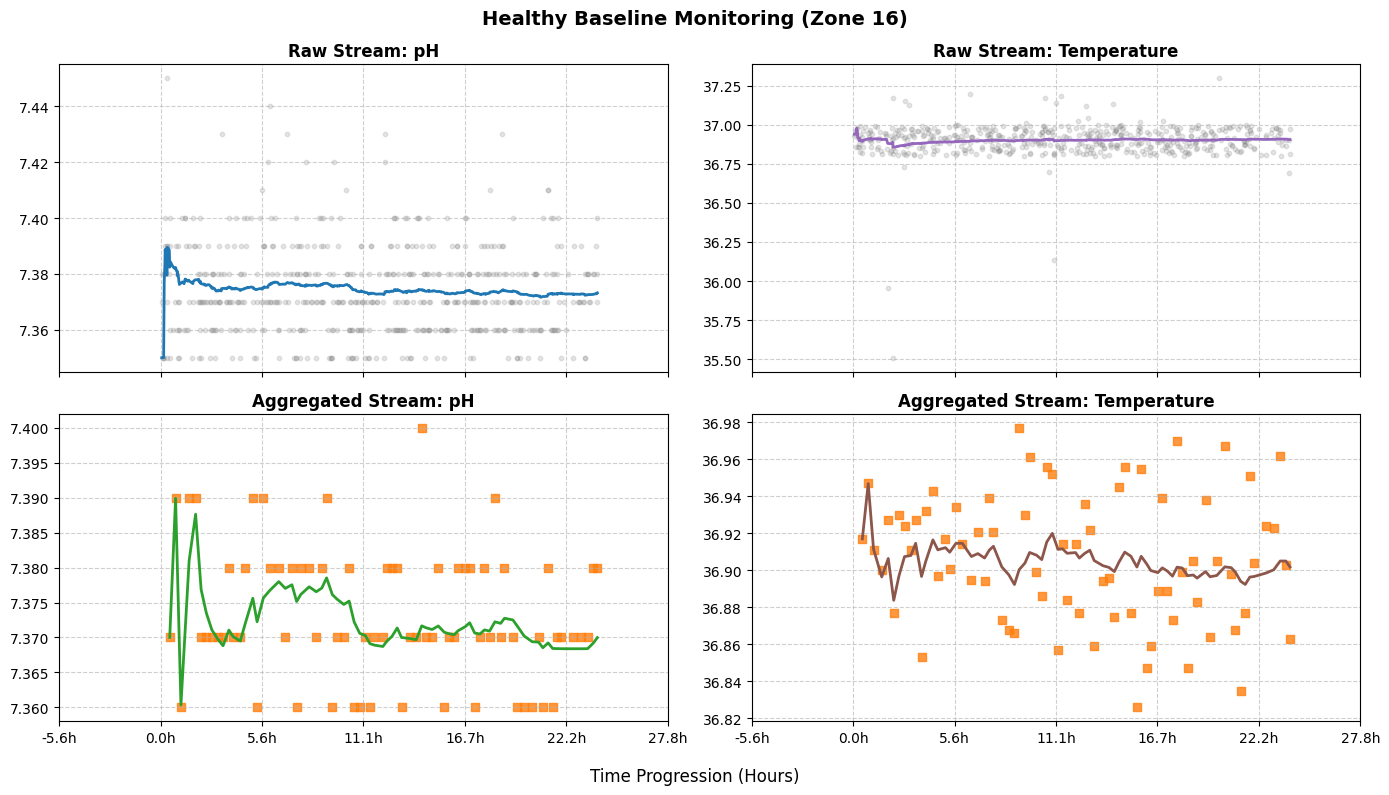

In [10]:
# --- 6. HEALTHY PATIENT (Combined Monitoring) ---
TARGET_ZONE = 16          
ALPHA_NOISE = 0.3
BETA_ERROR = 0.10        
TARGET_CONF = 70.0       
SAFE_START = 86400       # Pushed beyond 24h

print(f"--- 1. Running Healthy Baseline (Monitoring Zone {TARGET_ZONE}) ---")
simulator = DiseaseSimulator()

raw_df, agg_df, t_start = simulator.run_combined_disease(
    alpha=ALPHA_NOISE, 
    beta=BETA_ERROR, 
    disease_key='pyelo_combined',
    target_confidence=TARGET_CONF,
    safe_start_time=SAFE_START
)

if agg_df is not None and not agg_df.empty:
    print(f"\n--- 2. Running Whole-Body Anomaly Detection ---")
    
    detector = AnomalyDetector(
        alpha=ALPHA_NOISE, 
        beta=BETA_ERROR,
        target_confidence=TARGET_CONF,
        raw_drift_threshold=3.5,
        agg_persistence=4,
        agg_abs_drift_ph=0.10,    
        agg_abs_drift_temp=0.80
    )

    processed_raw_df, all_raw_alerts = detector.detect_combined_raw_stream(raw_df)
    processed_agg_df, all_agg_alerts = detector.detect_combined_aggregated_stream(agg_df)

    print("\n--- Detection Results ---")
    
    def print_combined_alerts(alert_dict, stream_name):
        print(f"\n[{stream_name} ALERTS]")
        if not alert_dict:
            print("  No anomalies detected in any zone. (Expected Healthy Behavior)")
            return
            
        for zone_id, times in alert_dict.items():
            print(f"  --> ZONE {zone_id} ALERT:")
            for param, t_det in times.items():
                if t_det is not None:
                    print(f"      - {param.upper()} FALSE POSITIVE: Flagged at Hour {t_det/3600:.2f}")

    print_combined_alerts(all_raw_alerts, "RAW STREAM")
    print_combined_alerts(all_agg_alerts, "AGGREGATED STREAM")

    print(f"\n--- 3. Generating Visualization ---")
    visualizer = AnomalyVisualizer()
    
    plot_det_raw = all_raw_alerts.get(TARGET_ZONE, {'ph': None, 'temp': None})
    plot_det_agg = all_agg_alerts.get(TARGET_ZONE, {'ph': None, 'temp': None})
    
    plot_raw_df = processed_raw_df[processed_raw_df['Zone'] == TARGET_ZONE]
    plot_agg_df = processed_agg_df[processed_agg_df['Zone'] == TARGET_ZONE]

    visualizer.plot_combined_comparison(
        raw_df=plot_raw_df, 
        agg_df=plot_agg_df, 
        det_raw=plot_det_raw, 
        det_agg=plot_det_agg, 
        title=f"Healthy Baseline Monitoring (Zone {TARGET_ZONE})"
    )